In [1]:
import pandas as pd
import scanpy as sc
import seaborn as sns 
import matplotlib.pyplot as plt

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/clustering_on_MI_genes"

junker_scores = pd.read_csv(f"{BASE}/junker_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
treutlein_scores = pd.read_csv(f"{BASE}/treutlein_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")

knoblich_day42_1_scores = pd.read_csv(f"{BASE}/knoblich_day42_1_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
knoblich_day42_2_scores = pd.read_csv(f"{BASE}/knoblich_day42_2_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")

knoblich_day16_1_scores = pd.read_csv(f"{BASE}/knoblich_day16_1_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
knoblich_day16_2_scores = pd.read_csv(f"{BASE}/knoblich_day16_2_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")

you_stage1_scores = pd.read_csv(f"{BASE}/you_stage1_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
you_stage2_scores = pd.read_csv(f"{BASE}/you_stage2_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
you_stage3_scores = pd.read_csv(f"{BASE}/you_stage3_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")
you_stage4_scores = pd.read_csv(f"{BASE}/you_stage4_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")

weinreb_scores = pd.read_csv(f"{BASE}/weinreb_accuracy_jaccard_scores_200iterations_200genes_fast_revision.csv")


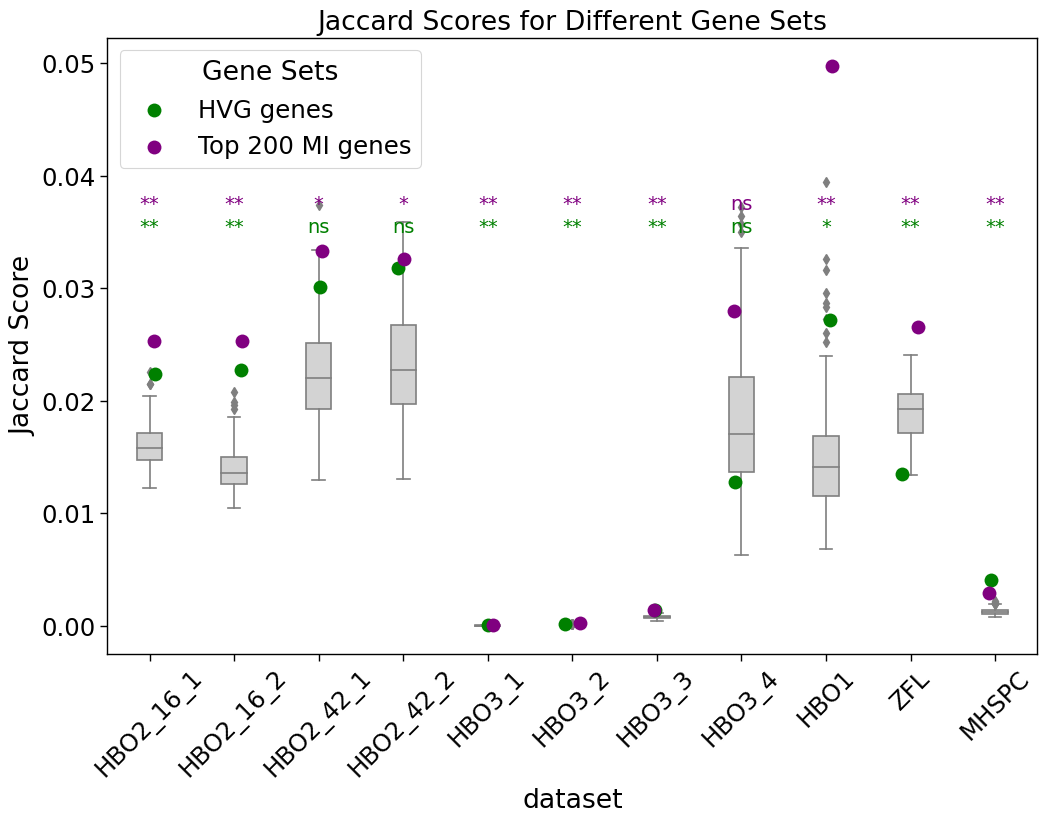

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Add dataset labels
junker_scores['dataset'] = 'ZFL'
knoblich_day42_2_scores['dataset'] = 'HBO2_42_2'
treutlein_scores['dataset'] = 'HBO1'
knoblich_day42_1_scores['dataset'] = 'HBO2_42_1'
knoblich_day16_1_scores['dataset'] = 'HBO2_16_1'
knoblich_day16_2_scores['dataset'] = 'HBO2_16_2'
you_stage1_scores['dataset'] = 'HBO3_1'
you_stage2_scores['dataset'] = 'HBO3_2'
you_stage3_scores['dataset'] = 'HBO3_3'
you_stage4_scores['dataset'] = 'HBO3_4'
weinreb_scores['dataset'] = 'MHSPC'

combined_scores = pd.concat([
    knoblich_day16_1_scores,
    knoblich_day16_2_scores,
    knoblich_day42_1_scores,
    knoblich_day42_2_scores,
    you_stage1_scores,
    you_stage2_scores,
    you_stage3_scores,
    you_stage4_scores,
    treutlein_scores,
    junker_scores,
    weinreb_scores
], ignore_index=True)


def calc_p_value_for_data_point(data, X_0):
    """
    Two-tailed empirical p-value using the sampled null distribution.
    Uses a +1 correction so p is never 0:
        p = (1 + #{|r - mu| >= |x0 - mu|}) / (N + 1)
    """
    r = np.asarray(data, dtype=float)
    mu = float(np.mean(r))
    obs = abs(float(X_0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))


# Map p-values to stars
def get_pval_stars(p_val):
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

# Visualization
sns.set_context("paper", font_scale=2)
plt.figure(figsize=(12, 8))

x_order = [
    'HBO2_16_1',
    'HBO2_16_2',
    'HBO2_42_1',
    'HBO2_42_2',
    'HBO3_1',
    'HBO3_2',
    'HBO3_3',
    'HBO3_4',
    'HBO1',
    'ZFL',
    'MHSPC'
]

random_genes_scores = combined_scores[combined_scores['gene_set'] == '200 random genes']
sns.boxplot(x="dataset", y='jaccard', data=random_genes_scores, color='lightgray', width=0.3, order = x_order)

# Define gene sets
gene_sets = ['HVG genes', 'Top 200 MI genes']
colors = ['green', 'purple']
y_offsets = {'HVG genes': 0.035, 'Top 200 MI genes': 0.037}
x_position_map = {name: i for i, name in enumerate(x_order)}

for gene_set, color in zip(gene_sets, colors):
    subset = combined_scores[combined_scores['gene_set'] == gene_set]
    sns.stripplot(x='dataset', y='jaccard', data=subset, color=color, label=gene_set, jitter=True, size=10, order = x_order)

    for dataset_name in x_order:
        null_dist = random_genes_scores[random_genes_scores['dataset'] == dataset_name]['jaccard'].values
        data_points = subset[subset['dataset'] == dataset_name]

        x_pos = x_position_map[dataset_name]
        jitter_width = 0.2

        for _, row in data_points.iterrows():
            p_val = calc_p_value_for_data_point(null_dist, row['jaccard'])
            star_label = get_pval_stars(p_val)
            x_jittered = x_pos 
            plt.text(x_jittered, y_offsets[gene_set], star_label, color=color, fontsize=14, ha='center')

# Legend and final layout
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), title='Gene Sets')
plt.xticks(rotation=45)
plt.ylabel('Jaccard Score')
plt.title('Jaccard Scores for Different Gene Sets')
plt.savefig('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/violins_jaccard_scores_with_stars_all_datasets.pdf', bbox_inches='tight')
plt.show()


BH correction performed separately across 11 datasets:
  - 11 tests for HVG genes
  - 11 tests for Top 200 MI genes


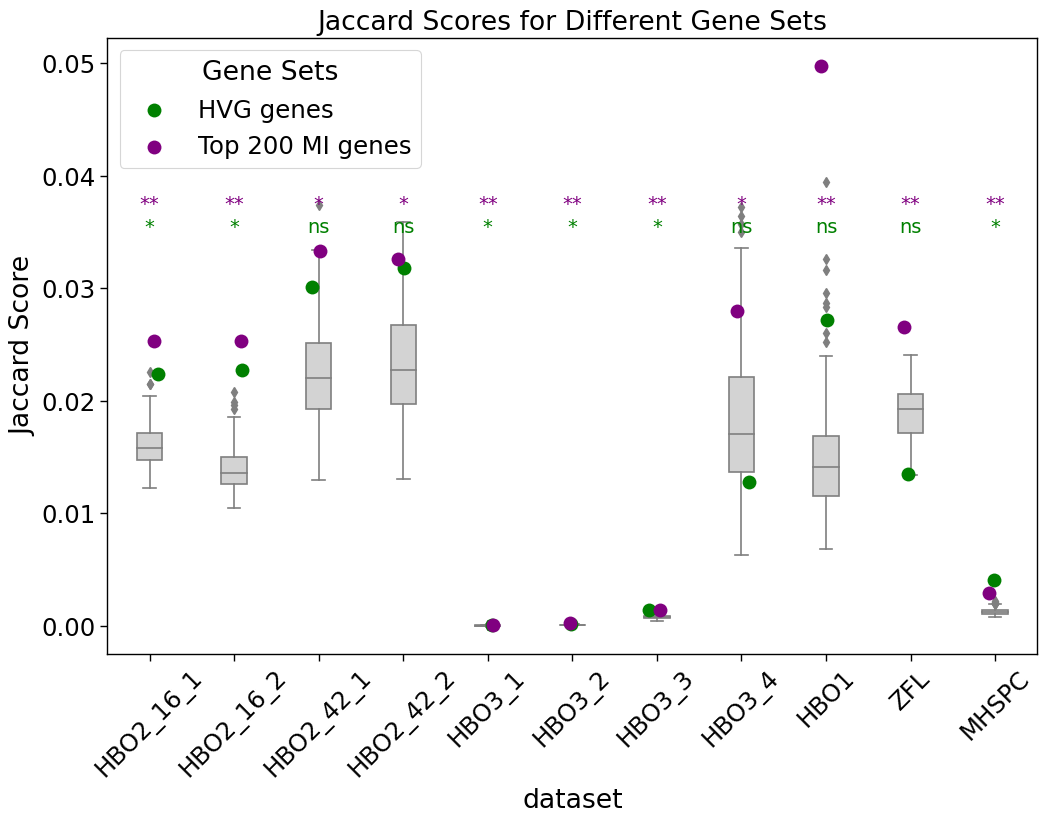

,dataset,gene_set,jaccard,p_raw,p_BH,significant_BH,stars_BH
0,HBO2_16_1,HVG genes,0.022404,0.009950,0.018242,True,*
1,HBO2_16_2,HVG genes,0.022782,0.004975,0.010945,True,*
2,HBO2_42_1,HVG genes,0.030098,0.039801,0.054726,False,ns
3,HBO2_42_2,HVG genes,0.031841,0.049751,0.060807,False,ns
4,HBO3_1,HVG genes,0.000102,0.004975,0.010945,True,*
5,HBO3_2,HVG genes,0.000210,0.004975,0.010945,True,*
6,HBO3_3,HVG genes,0.001384,0.004975,0.010945,True,*
7,HBO3_4,HVG genes,0.012794,0.791045,0.870149,False,ns
8,HBO1,HVG genes,0.027164,0.039801,0.054726,False,ns
9,ZFL,HVG genes,0.013478,0.995025,0.995025,False,ns


In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.stats.multitest import multipletests


# =========================================================
# Add dataset labels
# =========================================================

junker_scores['dataset'] = 'ZFL'
knoblich_day42_2_scores['dataset'] = 'HBO2_42_2'
treutlein_scores['dataset'] = 'HBO1'
knoblich_day42_1_scores['dataset'] = 'HBO2_42_1'
knoblich_day16_1_scores['dataset'] = 'HBO2_16_1'
knoblich_day16_2_scores['dataset'] = 'HBO2_16_2'
you_stage1_scores['dataset'] = 'HBO3_1'
you_stage2_scores['dataset'] = 'HBO3_2'
you_stage3_scores['dataset'] = 'HBO3_3'
you_stage4_scores['dataset'] = 'HBO3_4'
weinreb_scores['dataset'] = 'MHSPC'


combined_scores = pd.concat([
    knoblich_day16_1_scores,
    knoblich_day16_2_scores,
    knoblich_day42_1_scores,
    knoblich_day42_2_scores,
    you_stage1_scores,
    you_stage2_scores,
    you_stage3_scores,
    you_stage4_scores,
    treutlein_scores,
    junker_scores,
    weinreb_scores
], ignore_index=True)


# =========================================================
# Empirical p-value function
# =========================================================

def calc_p_value_for_data_point(data, X_0):
    """
    One-sided empirical p-value.

    Tests whether the observed Jaccard score is HIGHER
    than expected from the random-gene null distribution.

        H0: observed score is not higher than random
        H1: observed score is higher than random

    Uses +1 correction:
        p = (1 + #{r >= X_0}) / (N + 1)
    """
    r = np.asarray(data, dtype=float)

    more_extreme = np.sum(r >= float(X_0))

    return float(
        (1.0 + more_extreme) /
        (r.size + 1.0)
    )


# =========================================================
# Map BH-adjusted p-values to stars
# =========================================================

def get_pval_stars(p_val):

    if p_val > 0.05:
        return "ns"

    elif p_val > 0.01:
        return "*"

    elif p_val > 0.001:
        return "**"

    elif p_val > 0.0001:
        return "***"

    else:
        return "****"


# =========================================================
# Dataset / gene-set order
# =========================================================

x_order = [
    'HBO2_16_1',
    'HBO2_16_2',
    'HBO2_42_1',
    'HBO2_42_2',
    'HBO3_1',
    'HBO3_2',
    'HBO3_3',
    'HBO3_4',
    'HBO1',
    'ZFL',
    'MHSPC'
]


gene_sets = [
    'HVG genes',
    'Top 200 MI genes'
]


colors = [
    'green',
    'purple'
]


y_offsets = {
    'HVG genes': 0.035,
    'Top 200 MI genes': 0.037
}


x_position_map = {
    name: i
    for i, name in enumerate(x_order)
}


# =========================================================
# Random-gene null distributions
# =========================================================

random_genes_scores = combined_scores[
    combined_scores['gene_set'] == '200 random genes'
]


# =========================================================
# Calculate ALL raw empirical p-values first
# =========================================================

test_results = []


for gene_set in gene_sets:

    subset = combined_scores[
        combined_scores['gene_set'] == gene_set
    ]

    for dataset_name in x_order:

        # Null distribution for this dataset
        null_dist = random_genes_scores[
            random_genes_scores['dataset'] == dataset_name
        ]['jaccard'].dropna().values

        # Observed value(s) for this gene set
        data_points = subset[
            subset['dataset'] == dataset_name
        ]

        for row_index, row in data_points.iterrows():

            p_raw = calc_p_value_for_data_point(
                null_dist,
                row['jaccard']
            )

            test_results.append({
                'dataset': dataset_name,
                'gene_set': gene_set,
                'row_index': row_index,
                'jaccard': row['jaccard'],
                'p_raw': p_raw
            })


# =========================================================
# BH correction separately across the 11 datasets
# for each gene set
# =========================================================

stats_results = pd.DataFrame(test_results)

stats_results['p_BH'] = np.nan
stats_results['significant_BH'] = False

for gene_set in gene_sets:

    mask = stats_results['gene_set'] == gene_set

    reject, pvals_BH, _, _ = multipletests(
        stats_results.loc[mask, 'p_raw'].values,
        alpha=0.05,
        method='fdr_bh'
    )

    stats_results.loc[mask, 'p_BH'] = pvals_BH
    stats_results.loc[mask, 'significant_BH'] = reject


stats_results['stars_BH'] = stats_results['p_BH'].apply(
    get_pval_stars
)

print("BH correction performed separately across 11 datasets:")
print("  - 11 tests for HVG genes")
print("  - 11 tests for Top 200 MI genes")

# =========================================================
# Visualization
# =========================================================

sns.set_context(
    "paper",
    font_scale=2
)

plt.figure(
    figsize=(12, 8)
)


# ---------------------------------------------------------
# Random-gene null distribution
# ---------------------------------------------------------

sns.boxplot(
    x="dataset",
    y='jaccard',
    data=random_genes_scores,
    color='lightgray',
    width=0.3,
    order=x_order
)


# ---------------------------------------------------------
# HVG + Top MI points
# ---------------------------------------------------------

for gene_set, color in zip(
    gene_sets,
    colors
):

    subset = combined_scores[
        combined_scores['gene_set'] == gene_set
    ]

    sns.stripplot(
        x='dataset',
        y='jaccard',
        data=subset,
        color=color,
        label=gene_set,
        jitter=True,
        size=10,
        order=x_order
    )


    # -----------------------------------------------------
    # BH-corrected significance annotations
    # -----------------------------------------------------

    gene_stats = stats_results[
        stats_results['gene_set'] == gene_set
    ]

    for dataset_name in x_order:

        dataset_stats = gene_stats[
            gene_stats['dataset'] == dataset_name
        ]

        x_pos = x_position_map[
            dataset_name
        ]

        for _, stat_row in dataset_stats.iterrows():

            star_label = stat_row[
                'stars_BH'
            ]

            plt.text(
                x_pos,
                y_offsets[gene_set],
                star_label,
                color=color,
                fontsize=14,
                ha='center'
            )


# =========================================================
# Legend and final layout
# =========================================================

handles, labels = plt.gca().get_legend_handles_labels()

by_label = dict(
    zip(labels, handles)
)

plt.legend(
    by_label.values(),
    by_label.keys(),
    title='Gene Sets'
)

plt.xticks(
    rotation=45
)

plt.ylabel(
    'Jaccard Score'
)

plt.title(
    'Jaccard Scores for Different Gene Sets'
)


# =========================================================
# Save
# =========================================================

plt.savefig(
    '/fast/AG_Metzger/philipp/python_files/'
    'gene_signature/mutual_information_approach/'
    'November_25_ReDo/figures/'
    'violins_jaccard_scores_with_stars_all_datasets_with_BH.pdf',
    bbox_inches='tight'
)

plt.show()


# =========================================================
# Display raw + BH-corrected p-values
# =========================================================

display(
    stats_results[
        [
            'dataset',
            'gene_set',
            'jaccard',
            'p_raw',
            'p_BH',
            'significant_BH',
            'stars_BH'
        ]
    ].reset_index(drop=True)
)

In [10]:
import pandas as pd
import numpy as np

from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


# =========================================================
# Dataset order
# =========================================================

x_order = [
    'HBO2_16_1',
    'HBO2_16_2',
    'HBO2_42_1',
    'HBO2_42_2',
    'HBO3_1',
    'HBO3_2',
    'HBO3_3',
    'HBO3_4',
    'HBO1',
    'ZFL',
    'MHSPC'
]

gene_sets = [
    'HVG genes',
    'Top 200 MI genes'
]


# =========================================================
# Calculate mean random-gene Jaccard for each dataset
# =========================================================

random_means = (
    combined_scores[
        combined_scores['gene_set'] == '200 random genes'
    ]
    .groupby('dataset')['jaccard']
    .mean()
)


# =========================================================
# Calculate observed - random difference for each dataset
# =========================================================

difference_rows = []

for gene_set in gene_sets:

    for dataset in x_order:

        observed_values = combined_scores.loc[
            (combined_scores['dataset'] == dataset) &
            (combined_scores['gene_set'] == gene_set),
            'jaccard'
        ].dropna()

        if len(observed_values) == 0:
            continue

        # Should normally be one value.
        # Mean makes this robust if more than one is present.
        observed = observed_values.mean()

        random_mean = random_means.loc[dataset]

        difference = observed - random_mean

        difference_rows.append({
            'dataset': dataset,
            'gene_set': gene_set,
            'observed_jaccard': observed,
            'mean_random_jaccard': random_mean,
            'difference': difference
        })


differences_df = pd.DataFrame(difference_rows)


# =========================================================
# One-sided Wilcoxon signed-rank tests
#
# H0: median(observed - random) <= 0
# H1: median(observed - random) > 0
# =========================================================

test_results = []

for gene_set in gene_sets:

    diffs = differences_df.loc[
        differences_df['gene_set'] == gene_set,
        'difference'
    ].values

    statistic, p_raw = wilcoxon(
        diffs,
        alternative='greater'
    )

    test_results.append({
        'gene_set': gene_set,
        'n_datasets': len(diffs),
        'n_positive': np.sum(diffs > 0),
        'median_difference': np.median(diffs),
        'mean_difference': np.mean(diffs),
        'wilcoxon_statistic': statistic,
        'p_raw': p_raw
    })


global_stats = pd.DataFrame(test_results)


# =========================================================
# BH correction across the TWO global tests
# =========================================================

reject, p_BH, _, _ = multipletests(
    global_stats['p_raw'],
    alpha=0.05,
    method='fdr_bh'
)

global_stats['p_BH'] = p_BH
global_stats['significant_BH'] = reject


# =========================================================
# Stars from BH-adjusted p-values
# =========================================================

def get_pval_stars(p):
    if p > 0.05:
        return "ns"
    elif p > 0.01:
        return "*"
    elif p > 0.001:
        return "**"
    elif p > 0.0001:
        return "***"
    else:
        return "****"


global_stats['stars_BH'] = (
    global_stats['p_BH']
    .apply(get_pval_stars)
)


# =========================================================
# Show results
# =========================================================

print("Per-dataset differences:")
display(
    differences_df.sort_values(
        ['gene_set', 'dataset']
    ).reset_index(drop=True)
)

print("\nGlobal one-sided Wilcoxon tests:")
display(global_stats)

Per-dataset differences:


,dataset,gene_set,observed_jaccard,mean_random_jaccard,difference
0,HBO1,HVG genes,0.027164,0.014927,0.012237
1,HBO2_16_1,HVG genes,0.022404,0.015981,0.006423
2,HBO2_16_2,HVG genes,0.022782,0.013978,0.008804
3,HBO2_42_1,HVG genes,0.030098,0.022454,0.007643
4,HBO2_42_2,HVG genes,0.031841,0.023214,0.008626
5,HBO3_1,HVG genes,0.000102,0.000033,0.000069
6,HBO3_2,HVG genes,0.000210,0.000095,0.000115
7,HBO3_3,HVG genes,0.001384,0.000782,0.000601
8,HBO3_4,HVG genes,0.012794,0.017920,-0.005126
9,MHSPC,HVG genes,0.004088,0.001251,0.002837



Global one-sided Wilcoxon tests:


,gene_set,n_datasets,n_positive,median_difference,mean_difference,wilcoxon_statistic,p_raw,p_BH,significant_BH,stars_BH
0,HVG genes,11,9,0.002837,0.003335,55.0,0.026855,0.026855,True,*
1,Top 200 MI genes,11,11,0.009367,0.008712,66.0,0.000488,0.000977,True,***


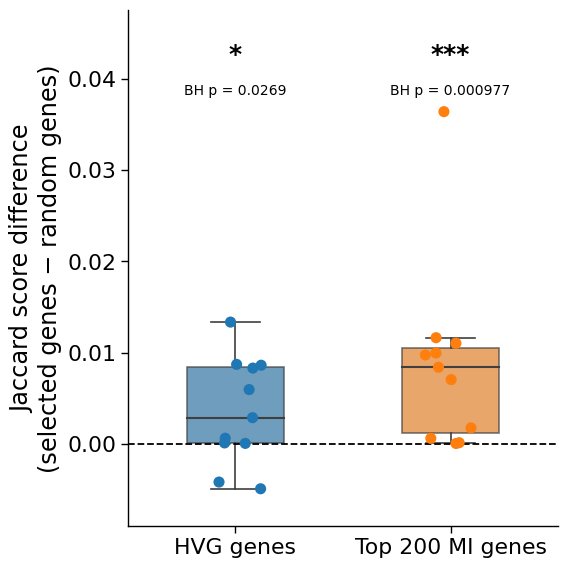

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


# =========================================================
# Plot settings
# =========================================================

sns.set_context("paper", font_scale=1.8)

plot_order = [
    'HVG genes',
    'Top 200 MI genes'
]

plt.figure(figsize=(6, 6))


# =========================================================
# Boxplots
# =========================================================

ax = sns.boxplot(
    data=differences_df,
    x='gene_set',
    y='difference',
    order=plot_order,
    width=0.45,
    showfliers=False,
    boxprops=dict(alpha=0.7),
    medianprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2)
)


# =========================================================
# Individual datasets
# =========================================================

sns.stripplot(
    data=differences_df,
    x='gene_set',
    y='difference',
    order=plot_order,
    size=8,
    jitter=0.12,
    ax=ax
)


# =========================================================
# Random-baseline reference
# =========================================================

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1.3,
    color='black'
)


# =========================================================
# BH-corrected significance annotations
# =========================================================

y_max = differences_df['difference'].max()
y_min = differences_df['difference'].min()

y_range = y_max - y_min

if y_range == 0:
    y_range = 1

annotation_y = y_max + 0.12 * y_range


for x_pos, gene_set in enumerate(plot_order):

    stat_row = global_stats.loc[
        global_stats['gene_set'] == gene_set
    ].iloc[0]

    stars = stat_row['stars_BH']
    p_bh = stat_row['p_BH']

    plt.text(
        x_pos,
        annotation_y,
        stars,
        ha='center',
        va='bottom',
        fontsize=18,
        fontweight='bold'
    )

    plt.text(
        x_pos,
        annotation_y - 0.045 * y_range,
        f"BH p = {p_bh:.3g}",
        ha='center',
        va='top',
        fontsize=10
    )


# =========================================================
# Aesthetics
# =========================================================

plt.ylabel(
    'Jaccard score difference\n(selected genes − random genes)'
)

plt.xlabel('')

plt.xticks(
    [0, 1],
    ['HVG genes', 'Top 200 MI genes']
)

plt.ylim(
    y_min - 0.1 * y_range,
    annotation_y + 0.15 * y_range
)

sns.despine()

plt.tight_layout()


# =========================================================
# Save
# =========================================================

plt.savefig(
    '/fast/AG_Metzger/philipp/python_files/'
    'gene_signature/mutual_information_approach/'
    'November_25_ReDo/figures/'
    'global_jaccard_difference_vs_random_wilcoxon_BH.pdf',
    bbox_inches='tight'
)

plt.show()

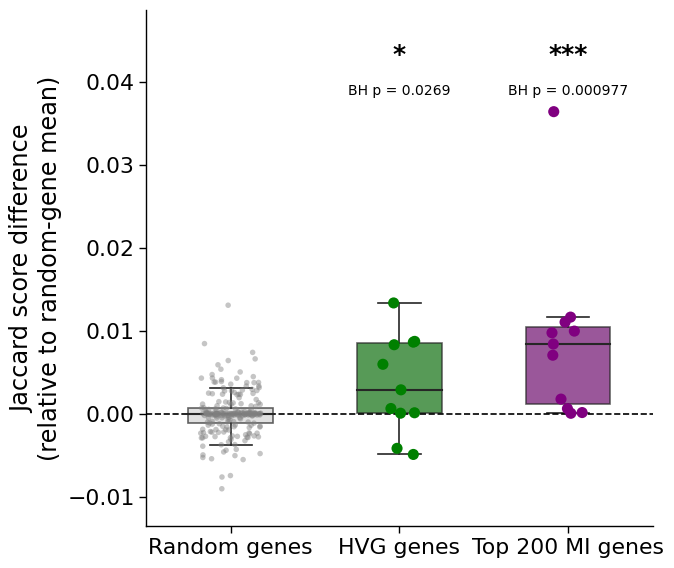

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# =========================================================
# Build plotting dataframe
# All values expressed relative to the dataset-specific
# mean random-gene Jaccard score
# =========================================================

plot_rows = []


# ---------------------------------------------------------
# Random gene sets
# ---------------------------------------------------------

for dataset in x_order:

    random_values = combined_scores.loc[
        (combined_scores['dataset'] == dataset) &
        (combined_scores['gene_set'] == '200 random genes'),
        'jaccard'
    ].dropna()

    random_mean = random_values.mean()

    for value in random_values:

        plot_rows.append({
            'dataset': dataset,
            'gene_set': 'Random genes',
            'difference': value - random_mean
        })


# ---------------------------------------------------------
# HVG + Top MI
# ---------------------------------------------------------

for _, row in differences_df.iterrows():

    plot_rows.append({
        'dataset': row['dataset'],
        'gene_set': row['gene_set'],
        'difference': row['difference']
    })


plot_df = pd.DataFrame(plot_rows)


# =========================================================
# Plot settings
# =========================================================

sns.set_context("paper", font_scale=1.8)

plot_order = [
    'Random genes',
    'HVG genes',
    'Top 200 MI genes'
]

palette = {
    'Random genes': 'lightgray',
    'HVG genes': 'green',
    'Top 200 MI genes': 'purple'
}

plt.figure(figsize=(7, 6))


# =========================================================
# Boxplots
# =========================================================

ax = sns.boxplot(
    data=plot_df,
    x='gene_set',
    y='difference',
    order=plot_order,
    palette=palette,
    width=0.5,
    showfliers=False,
    boxprops=dict(alpha=0.7),
    medianprops=dict(linewidth=1.5),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2)
)


# =========================================================
# Individual points
# =========================================================

# Random-gene realizations
sns.stripplot(
    data=plot_df[
        plot_df['gene_set'] == 'Random genes'
    ],
    x='gene_set',
    y='difference',
    order=plot_order,
    color='gray',
    size=4,
    alpha=0.45,
    jitter=0.18,
    ax=ax
)

# HVG + Top MI: one point per dataset
for gene_set, color in [
    ('HVG genes', 'green'),
    ('Top 200 MI genes', 'purple')
]:

    sns.stripplot(
        data=plot_df[
            plot_df['gene_set'] == gene_set
        ],
        x='gene_set',
        y='difference',
        order=plot_order,
        color=color,
        size=8,
        jitter=0.10,
        ax=ax
    )


# =========================================================
# Random expectation
# =========================================================

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1.2,
    color='black'
)


# =========================================================
# BH-corrected global significance annotations
# =========================================================

y_max = plot_df['difference'].max()
y_min = plot_df['difference'].min()

y_range = y_max - y_min

if y_range == 0:
    y_range = 1

annotation_y = y_max + 0.12 * y_range


# Only HVG and MI were statistically tested
for x_pos, gene_set in [
    (1, 'HVG genes'),
    (2, 'Top 200 MI genes')
]:

    stat_row = global_stats.loc[
        global_stats['gene_set'] == gene_set
    ].iloc[0]

    stars = stat_row['stars_BH']
    p_bh = stat_row['p_BH']

    plt.text(
        x_pos,
        annotation_y,
        stars,
        ha='center',
        va='bottom',
        fontsize=18,
        fontweight='bold'
    )

    plt.text(
        x_pos,
        annotation_y - 0.045 * y_range,
        f"BH p = {p_bh:.3g}",
        ha='center',
        va='top',
        fontsize=10
    )


# =========================================================
# Aesthetics
# =========================================================

plt.ylabel(
    'Jaccard score difference\n(relative to random-gene mean)'
)

plt.xlabel('')

plt.xticks(
    [0, 1, 2],
    [
        'Random genes',
        'HVG genes',
        'Top 200 MI genes'
    ]
)

plt.ylim(
    y_min - 0.10 * y_range,
    annotation_y + 0.15 * y_range
)

sns.despine()
plt.tight_layout()


# =========================================================
# Save
# =========================================================

plt.savefig(
    '/fast/AG_Metzger/philipp/python_files/'
    'gene_signature/mutual_information_approach/'
    'November_25_ReDo/figures/'
    'global_jaccard_random_HVG_MI_wilcoxon_BH.pdf',
    bbox_inches='tight'
)

plt.show()